In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/Fake.csv
/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/True.csv
/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/config.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/tokenizer.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/metadata.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/model.weights.h5
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/assets/tokenizer/vocabulary.txt


In [2]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/Fake.csv
/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/True.csv
/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/config.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/tokenizer.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/metadata.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/model.weights.h5
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/assets/tokenizer/vocabulary.txt


In [3]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/Fake.csv
/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/True.csv
/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/config.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/tokenizer.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/metadata.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/model.weights.h5
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/assets/tokenizer/vocabulary.txt


In [4]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix

In [5]:
fake = pd.read_csv("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/Fake.csv") 
real = pd.read_csv("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/True.csv")

fake["label"] = 0   
real["label"] = 1   

df = pd.concat([fake, real])[["title", "text", "label"]]
df = df.dropna().drop_duplicates(subset="text")
df["content"] = df["title"] + " " + df["text"]
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)
print(df["label"].value_counts())

(38646, 4)
label
1    21191
0    17455
Name: count, dtype: int64


In [6]:
fake = pd.read_csv("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/Fake.csv") 
real = pd.read_csv("/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/True.csv")

fake["label"] = 0   
real["label"] = 1   

df = pd.concat([fake, real])[["title", "text", "label"]]
df = df.dropna().drop_duplicates(subset="text")
df["content"] = df["title"] + " " + df["text"]
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)
print(df["label"].value_counts())

(38646, 4)
label
1    21191
0    17455
Name: count, dtype: int64


In [7]:
def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"\(reuters\)|reuters", " ", t)
    t = re.sub(r"21st century wire|featured image|getty images|via", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["content"].apply(clean)
df[["clean", "label"]].head()

,clean,label
0,kenya watchdog says investigating police over ...,1
1,trump bars door to refugees visitors from seve...,1
2,kosovo parties sign deal to form government en...,1
3,trump says no rush to get healthcare legislati...,1
4,letter to the editor claims hillary is unfit b...,0


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2,
    stratify=df["label"], random_state=42)

              precision    recall  f1-score   support

           0       0.99      0.97      0.98      3491
           1       0.98      0.99      0.98      4239

    accuracy                           0.98      7730
   macro avg       0.98      0.98      0.98      7730
weighted avg       0.98      0.98      0.98      7730



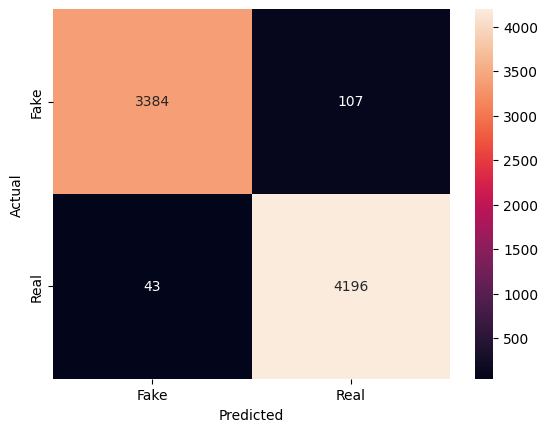

In [9]:
model = make_pipeline(
    TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 2)),
    LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

pred = model.predict(X_test)
print(classification_report(y_test, pred))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d",
            xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [10]:
tfidf = model.named_steps["tfidfvectorizer"]
clf = model.named_steps["logisticregression"]
words = np.array(tfidf.get_feature_names_out())
order = np.argsort(clf.coef_[0])

print("Words pointing to FAKE:", words[order[:25]])
print("Words pointing to REAL:", words[order[-25:]])

Words pointing to FAKE: ['video' 'just' 'gop' 'read' 'hillary' 'watch' 'president trump' 'like'
 'america' 'mr' 'obama' 'president obama' 'com' 'fact' 'american'
 'breaking' 'didn' 'rep' 'isis' 'pic' 'doesn' 'twitter com' 'pic twitter'
 'know' 'isn']
Words pointing to REAL: ['britain' 'court' 'told reporters' 'moscow' 'reporters' 'democratic'
 'london' 'president barack' 'comment' 'told' 'said statement' 'spokesman'
 'washington president' 'nov' 'presidential' 'minister' 'monday' 'friday'
 'republican' 'thursday' 'tuesday' 'wednesday' 'president donald'
 'washington' 'said']


In [11]:
days = r"monday|tuesday|wednesday|thursday|friday|saturday|sunday"
months = r"january|february|march|april|may|june|july|august|september|october|november|december|jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec"
places = r"washington|london|moscow|new york|beijing|brussels|berlin|paris"

def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"pic\.twitter\.com\S*|twitter\.com\S*", " ", t)
    t = re.sub(r"\(reuters\)|reuters", " ", t)
    t = re.sub(r"21st century wire|featured image|getty images|image via|via", " ", t)
    t = re.sub(rf"\b({days}|{months}|{places})\b", " ", t)
    t = re.sub(r"\b(mr|mrs|ms)\b", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["content"].apply(clean)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2,
    stratify=df["label"], random_state=42)

              precision    recall  f1-score   support

           0       0.98      0.97      0.98      3491
           1       0.97      0.99      0.98      4239

    accuracy                           0.98      7730
   macro avg       0.98      0.98      0.98      7730
weighted avg       0.98      0.98      0.98      7730



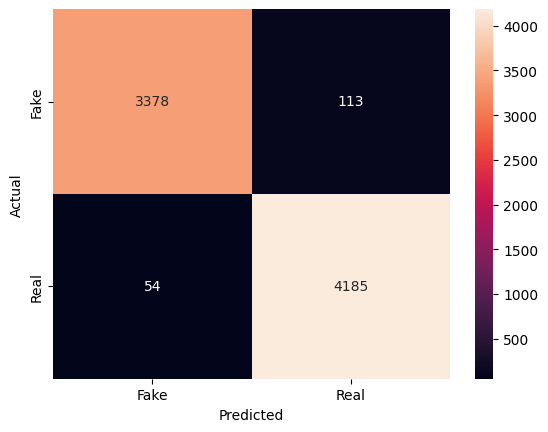

In [13]:
model = make_pipeline(
    TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 2)),
    LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

pred = model.predict(X_test)
print(classification_report(y_test, pred))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d",
            xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [14]:
tfidf = model.named_steps["tfidfvectorizer"]
clf = model.named_steps["logisticregression"]
words = np.array(tfidf.get_feature_names_out())
order = np.argsort(clf.coef_[0])

print("Words pointing to FAKE:", words[order[:20]])
print("Words pointing to REAL:", words[order[-20:]])

Words pointing to FAKE: ['video' 'just' 'gop' 'read' 'hillary' 'watch' 'president trump' 'like'
 'america' 'obama' 'president obama' 'breaking' 'didn' 'fact' 'american'
 'rep' 'isis' 'doesn' 'isn' 'know']
Words pointing to REAL: ['house representatives' 'agency' 'representatives' 'court' 'britain'
 'senate' 'trump said' 'comment' 'told reporters' 'democratic' 'reporters'
 'president barack' 'said statement' 'told' 'spokesman' 'minister'
 'presidential' 'republican' 'president donald' 'said']


In [15]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)
from sklearn.metrics import accuracy_score, f1_score

train_small = pd.DataFrame({"text": X_train, "label": y_train}).sample(15000, random_state=42)
test_small  = pd.DataFrame({"text": X_test,  "label": y_test}).sample(3000, random_state=42)

name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)

def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=256)

train_ds = Dataset.from_pandas(train_small.reset_index(drop=True)).map(tokenize, batched=True)
test_ds  = Dataset.from_pandas(test_small.reset_index(drop=True)).map(tokenize, batched=True)

def metrics(p):
    preds = p.predictions.argmax(axis=1)
    return {"accuracy": accuracy_score(p.label_ids, preds),
            "f1": f1_score(p.label_ids, preds)}

mdl = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)

args = TrainingArguments(
    output_dir="/kaggle/working/out",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    learning_rate=2e-5,
    eval_strategy="epoch",     # if you get an error, change to evaluation_strategy
    save_strategy="no",
    fp16=True,
    report_to="none")

trainer = Trainer(model=mdl, args=args, train_dataset=train_ds,
                  eval_dataset=test_ds, compute_metrics=metrics)
trainer.train()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

...

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super(

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.117217,0.987333,0.988415
2,0.177409,0.111906,0.989000,0.989997


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


TrainOutput(global_step=938, training_loss=0.11116876785180715, metrics={'train_runtime': 431.3012, 'train_samples_per_second': 69.557, 'train_steps_per_second': 2.175, 'total_flos': 1987010979840000.0, 'train_loss': 0.11116876785180715, 'epoch': 2.0})

In [16]:
import urllib.request
print(urllib.request.urlopen("https://huggingface.co").status)

200


In [17]:
import urllib.request
print(urllib.request.urlopen("https://huggingface.co").status)

200


In [18]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    if "config.json" in files and "vocab.txt" in files:
        print(root)

In [19]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    if "fake-and-real" in root:
        continue   # skip the news dataset
    print(root, files[:8])

/kaggle/input []
/kaggle/input/datasets []
/kaggle/input/datasets/clmentbisaillon []
/kaggle/input/datasets/nitaisatapathy []
/kaggle/input/datasets/nitaisatapathy/welfake-dataset ['WELFake_Dataset.csv']
/kaggle/input/models []
/kaggle/input/models/keras []
/kaggle/input/models/keras/distil_bert []
/kaggle/input/models/keras/distil_bert/keras []
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased []
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3 ['config.json', 'tokenizer.json', 'metadata.json', 'model.weights.h5']
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/assets []
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/assets/tokenizer ['vocabulary.txt']


In [20]:
import keras_hub, keras
print(keras_hub.__version__, keras.__version__)

0.26.0 3.13.2


In [21]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.metrics import accuracy_score, f1_score

tfidf = TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 2))
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Naive Bayes": MultinomialNB(),
    "Passive Aggressive": PassiveAggressiveClassifier(max_iter=50, random_state=42),
}

rows = []
for n, m in models.items():
    m.fit(Xtr, y_train)
    p = m.predict(Xte)
    rows.append([n, accuracy_score(y_test, p), f1_score(y_test, p)])

results = pd.DataFrame(rows, columns=["Model", "Accuracy", "F1"]).round(4)
print(results)

                 Model  Accuracy      F1
0  Logistic Regression    0.9784  0.9804
1           Linear SVM    0.9867  0.9879
2          Naive Bayes    0.9440  0.9485
3   Passive Aggressive    0.9867  0.9879


In [22]:
results_before = results.copy()

In [23]:
days = r"monday|tuesday|wednesday|thursday|friday|saturday|sunday"
months = r"january|february|march|april|may|june|july|august|september|october|november|december|jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec"
places = r"washington|london|moscow|new york|beijing|brussels|berlin|paris"

def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"pic\.twitter\.com\S*|twitter\.com\S*", " ", t)
    t = re.sub(r"\(reuters\)|reuters", " ", t)
    t = re.sub(r"21st century wire|featured image|getty images|image via|via", " ", t)
    t = re.sub(rf"\b({days}|{months}|{places})\b", " ", t)
    t = re.sub(r"\b(mr|mrs|ms)\b", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df["content"].apply(clean)

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2,
    stratify=df["label"], random_state=42)

In [24]:
print(results_before)
print(results)

                 Model  Accuracy      F1
0  Logistic Regression    0.9784  0.9804
1           Linear SVM    0.9867  0.9879
2          Naive Bayes    0.9440  0.9485
3   Passive Aggressive    0.9867  0.9879
                 Model  Accuracy      F1
0  Logistic Regression    0.9784  0.9804
1           Linear SVM    0.9867  0.9879
2          Naive Bayes    0.9440  0.9485
3   Passive Aggressive    0.9867  0.9879


In [25]:
print("BEFORE extra cleaning")
print(results_before)
print("AFTER extra cleaning")
print(results)

BEFORE extra cleaning
                 Model  Accuracy      F1
0  Logistic Regression    0.9784  0.9804
1           Linear SVM    0.9867  0.9879
2          Naive Bayes    0.9440  0.9485
3   Passive Aggressive    0.9867  0.9879
AFTER extra cleaning
                 Model  Accuracy      F1
0  Logistic Regression    0.9784  0.9804
1           Linear SVM    0.9867  0.9879
2          Naive Bayes    0.9440  0.9485
3   Passive Aggressive    0.9867  0.9879


In [26]:
# 1. rebuild cleaned text with the NEW clean() function
df["clean"] = df["content"].apply(clean)

# 2. quick check: the new cleaning should remove day names
print("Rows still containing 'monday':", df["clean"].str.contains(r"\bmonday\b").sum())

# 3. split again
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2,
    stratify=df["label"], random_state=42)

# 4. retrain all models on the new text
tfidf = TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 2))
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Naive Bayes": MultinomialNB(),
    "Passive Aggressive": PassiveAggressiveClassifier(max_iter=50, random_state=42),
}

rows = []
for n, m in models.items():
    m.fit(Xtr, y_train)
    p = m.predict(Xte)
    rows.append([n, accuracy_score(y_test, p), f1_score(y_test, p)])

results_after = pd.DataFrame(rows, columns=["Model", "Accuracy", "F1"]).round(4)
print("AFTER extra cleaning")
print(results_after)

Rows still containing 'monday': 0
AFTER extra cleaning
                 Model  Accuracy      F1
0  Logistic Regression    0.9784  0.9804
1           Linear SVM    0.9867  0.9879
2          Naive Bayes    0.9440  0.9485
3   Passive Aggressive    0.9867  0.9879


In [27]:
def clean_old(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"\(reuters\)|reuters", " ", t)
    t = re.sub(r"21st century wire|featured image|getty images|via", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def run_all(clean_fn, label):
    text = df["content"].apply(clean_fn)
    Xa, Xb, ya, yb = train_test_split(text, df["label"], test_size=0.2,
                                      stratify=df["label"], random_state=42)
    tf = TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 2))
    A, B = tf.fit_transform(Xa), tf.transform(Xb)
    ms = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "Linear SVM": LinearSVC(),
          "Naive Bayes": MultinomialNB(),
          "Passive Aggressive": PassiveAggressiveClassifier(max_iter=50, random_state=42)}
    rows = []
    for n, m in ms.items():
        m.fit(A, ya)
        p = m.predict(B)
        rows.append([n, accuracy_score(yb, p), f1_score(yb, p)])
    out = pd.DataFrame(rows, columns=["Model", "Accuracy", "F1"]).round(4)
    print(label); print(out)

run_all(clean_old, "OLD light cleaning")
run_all(clean, "NEW strong cleaning")

OLD light cleaning
                 Model  Accuracy      F1
0  Logistic Regression    0.9806  0.9824
1           Linear SVM    0.9898  0.9907
2          Naive Bayes    0.9481  0.9523
3   Passive Aggressive    0.9894  0.9903
NEW strong cleaning
                 Model  Accuracy      F1
0  Logistic Regression    0.9784  0.9804
1           Linear SVM    0.9867  0.9879
2          Naive Bayes    0.9440  0.9485
3   Passive Aggressive    0.9867  0.9879


In [28]:
for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if "WELFake" in f:
            print(os.path.join(root, f))

/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv


In [29]:
from sklearn.metrics import classification_report

w = pd.read_csv("/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv").dropna(subset=["text"])
w["title"] = w["title"].fillna("")
w["clean"] = (w["title"] + " " + w["text"]).apply(clean)
w = w.sample(5000, random_state=42)

# Retrain best model on ALL your ISOT data with the strong cleaning
tf = TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 2))
A = tf.fit_transform(df["clean"])
svm = LinearSVC().fit(A, df["label"])

pred = svm.predict(tf.transform(w["clean"]))

print("WELFake labels count:\n", w["label"].value_counts())
print("Accuracy if 1 = real:", accuracy_score(w["label"], pred))
print("Accuracy if 1 = fake:", accuracy_score(1 - w["label"], pred))

WELFake labels count:
 label
1    2583
0    2417
Name: count, dtype: int64
Accuracy if 1 = real: 0.1422
Accuracy if 1 = fake: 0.8578


In [30]:
from sklearn.metrics import classification_report, confusion_matrix

w["true"] = 1 - w["label"]      # flip so that 0 = fake, 1 = real, same as our model
print(classification_report(w["true"], pred, target_names=["Fake", "Real"]))
print(confusion_matrix(w["true"], pred))

              precision    recall  f1-score   support

        Fake       0.81      0.96      0.87      2583
        Real       0.94      0.75      0.84      2417

    accuracy                           0.86      5000
   macro avg       0.87      0.85      0.86      5000
weighted avg       0.87      0.86      0.86      5000

[[2468  115]
 [ 596 1821]]


In [31]:
w_all = pd.read_csv("/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv").dropna(subset=["text"])
w_all["title"] = w_all["title"].fillna("")
w_all["clean"] = (w_all["title"] + " " + w_all["text"]).apply(clean)
w_all["label"] = 1 - w_all["label"]          # fix direction: 0 = fake, 1 = real

w_all = w_all.sample(20000, random_state=42)  # keeps it fast
w_train, w_test = train_test_split(w_all, test_size=0.25, random_state=42, stratify=w_all["label"])

combined_x = pd.concat([df["clean"], w_train["clean"]])
combined_y = pd.concat([df["label"], w_train["label"]])

tf2 = TfidfVectorizer(stop_words="english", max_features=50000, ngram_range=(1, 2))
A2 = tf2.fit_transform(combined_x)
final = LinearSVC().fit(A2, combined_y)

p2 = final.predict(tf2.transform(w_test["clean"]))
print("Accuracy on held-out WELFake:", accuracy_score(w_test["label"], p2))
print(classification_report(w_test["label"], p2, target_names=["Fake", "Real"]))

Accuracy on held-out WELFake: 0.9386
              precision    recall  f1-score   support

        Fake       0.92      0.97      0.94      2576
        Real       0.96      0.91      0.93      2424

    accuracy                           0.94      5000
   macro avg       0.94      0.94      0.94      5000
weighted avg       0.94      0.94      0.94      5000



In [32]:
import joblib
joblib.dump({"vectorizer": tf2, "model": final}, "/kaggle/working/fake_news_model.pkl")

['/kaggle/working/fake_news_model.pkl']

In [33]:
def predict(text):
    x = tf2.transform([clean(text)])
    score = final.decision_function(x)[0]
    return ("Real" if score > 0 else "Fake"), round(abs(score), 2)

print(predict("Paste any news article text here"))

('Fake', np.float64(1.06))


In [34]:
def predict(text):
    x = tf2.transform([clean(text)])
    score = float(final.decision_function(x)[0])
    return ("Real" if score > 0 else "Fake"), round(abs(score), 2)

In [35]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [36]:
import os, re, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

# ---------- cleaning ----------
days = r"monday|tuesday|wednesday|thursday|friday|saturday|sunday"
months = r"january|february|march|april|may|june|july|august|september|october|november|december|jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec"
places = r"washington|london|moscow|new york|beijing|brussels|berlin|paris"

def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"pic\.twitter\.com\S*|twitter\.com\S*", " ", t)
    t = re.sub(r"\(reuters\)|reuters", " ", t)
    t = re.sub(r"21st century wire|featured image|getty images|image via|via", " ", t)
    t = re.sub(rf"\b({days}|{months}|{places})\b", " ", t)
    t = re.sub(r"\b(mr|mrs|ms)\b", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

# ---------- ISOT ----------
base = "/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/"
fake = pd.read_csv(base + "Fake.csv"); fake["label"] = 0
real = pd.read_csv(base + "True.csv"); real["label"] = 1
df = pd.concat([fake, real])[["title", "text", "label"]].dropna().drop_duplicates(subset="text")
df["clean"] = (df["title"] + " " + df["text"]).apply(clean)

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=42)

# ---------- WELFake (unseen test set) ----------
w = pd.read_csv("/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv").dropna(subset=["text"])
w["title"] = w["title"].fillna("")
w["clean"] = (w["title"] + " " + w["text"]).apply(clean)
w["label"] = 1 - w["label"]            # fixed direction: 0 = fake, 1 = real
w = w.sample(5000, random_state=42)

print(df.shape, w.shape)

(38646, 4) (5000, 5)


In [37]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

MAXLEN, VOCAB = 256, 30000

vec = layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=MAXLEN)
vec.adapt(X_train.values)                     # learns the vocabulary from training text only

def prep(s): return vec(tf.constant(s.values)).numpy()

Xtr, Xte, Xw = prep(X_train), prep(X_test), prep(w["clean"])
ytr, yte, yw = y_train.values, y_test.values, w["label"].values

I0000 00:00:1792650183.190589      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 11176 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792650183.196707      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 12080 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf = TfidfVectorizer(stop_words="english", max_features=20000, ngram_range=(1, 2))
Atr = tf.fit_transform(X_train).astype("float32")
Ate = tf.transform(X_test).astype("float32")
Aw  = tf.transform(w["clean"]).astype("float32")

ann = keras.Sequential([
    layers.Input(shape=(20000,)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")])
ann.compile("adam", "binary_crossentropy", metrics=["accuracy"])

ann.fit(Atr.toarray(), ytr, validation_split=0.1, epochs=4, batch_size=128,
        callbacks=[keras.callbacks.EarlyStopping(patience=1, restore_best_weights=True)], verbose=2)

Epoch 1/4


I0000 00:00:1792650235.516121    2809 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


218/218 - 6s - 29ms/step - accuracy: 0.9523 - loss: 0.1469 - val_accuracy: 0.9842 - val_loss: 0.0503
Epoch 2/4
218/218 - 1s - 6ms/step - accuracy: 0.9958 - loss: 0.0151 - val_accuracy: 0.9842 - val_loss: 0.0559


In [39]:
def build(kind):
    inp = keras.Input(shape=(MAXLEN,))
    x = layers.Embedding(VOCAB, 100)(inp)
    if kind == "Embedding + Average":
        x = layers.GlobalAveragePooling1D()(x)
    elif kind == "CNN":
        x = layers.Conv1D(128, 5, activation="relu")(x)
        x = layers.GlobalMaxPooling1D()(x)
    elif kind == "BiGRU":
        x = layers.Bidirectional(layers.GRU(64))(x)
    elif kind == "BiLSTM":
        x = layers.Bidirectional(layers.LSTM(64))(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inp, out)
    m.compile("adam", "binary_crossentropy", metrics=["accuracy"])
    return m

trained = {}
rows = []
for kind in ["Embedding + Average", "CNN", "BiGRU", "BiLSTM"]:
    print("=== training", kind)
    m = build(kind)
    m.fit(Xtr, ytr, validation_split=0.1, epochs=4, batch_size=64,
          callbacks=[keras.callbacks.EarlyStopping(patience=1, restore_best_weights=True)], verbose=2)
    trained[kind] = m
    p1 = (m.predict(Xte, verbose=0).ravel() > 0.5).astype(int)
    p2 = (m.predict(Xw,  verbose=0).ravel() > 0.5).astype(int)
    rows.append([kind, accuracy_score(yte, p1), f1_score(yte, p1), accuracy_score(yw, p2), f1_score(yw, p2)])

=== training Embedding + Average
Epoch 1/4
435/435 - 5s - 12ms/step - accuracy: 0.9164 - loss: 0.2394 - val_accuracy: 0.9677 - val_loss: 0.0948
Epoch 2/4
435/435 - 1s - 3ms/step - accuracy: 0.9773 - loss: 0.0675 - val_accuracy: 0.9783 - val_loss: 0.0718
Epoch 3/4
435/435 - 1s - 3ms/step - accuracy: 0.9853 - loss: 0.0462 - val_accuracy: 0.9635 - val_loss: 0.0969
=== training CNN
Epoch 1/4


2026-10-22 06:24:15.187268: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[100,128,1,5]{3,2,1,0}, u8[0]{0}) custom-call(f32[100,64,1,256]{3,2,1,0}, f32[128,64,1,252]{3,2,1,0}), window={size=1x252}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-22 06:24:15.389551: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.202401334s
Trying algorithm eng3{k11=2} for conv (f32[100,128,1,5]{3,2,1,0}, u8[0]{0}) custom-call(f32[100,64,1,256]{3,2,1,0}, f32[128,64,1,252]{3,2,1,0}), window={size=1x252}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_o

435/435 - 10s - 24ms/step - accuracy: 0.9142 - loss: 0.1955 - val_accuracy: 0.9732 - val_loss: 0.0728
Epoch 2/4
435/435 - 2s - 5ms/step - accuracy: 0.9861 - loss: 0.0408 - val_accuracy: 0.9822 - val_loss: 0.0561
Epoch 3/4
435/435 - 2s - 5ms/step - accuracy: 0.9958 - loss: 0.0134 - val_accuracy: 0.9799 - val_loss: 0.0718
=== training BiGRU
Epoch 1/4
435/435 - 14s - 31ms/step - accuracy: 0.9436 - loss: 0.1292 - val_accuracy: 0.9654 - val_loss: 0.1127
Epoch 2/4
435/435 - 9s - 20ms/step - accuracy: 0.9904 - loss: 0.0305 - val_accuracy: 0.9796 - val_loss: 0.0628
Epoch 3/4
435/435 - 9s - 21ms/step - accuracy: 0.9967 - loss: 0.0109 - val_accuracy: 0.9780 - val_loss: 0.0719
=== training BiLSTM
Epoch 1/4
435/435 - 12s - 27ms/step - accuracy: 0.9464 - loss: 0.1242 - val_accuracy: 0.9845 - val_loss: 0.0460
Epoch 2/4
435/435 - 9s - 21ms/step - accuracy: 0.9940 - loss: 0.0212 - val_accuracy: 0.9767 - val_loss: 0.0686


In [40]:
p1 = (ann.predict(Ate.toarray(), verbose=0).ravel() > 0.5).astype(int)
p2 = (ann.predict(Aw.toarray(),  verbose=0).ravel() > 0.5).astype(int)
rows.insert(0, ["ANN (TF-IDF)", accuracy_score(yte, p1), f1_score(yte, p1), accuracy_score(yw, p2), f1_score(yw, p2)])

results_dl = pd.DataFrame(rows, columns=["Model", "ISOT acc", "ISOT F1", "WELFake acc", "WELFake F1"]).round(4)
print(results_dl)

                 Model  ISOT acc  ISOT F1  WELFake acc  WELFake F1
0         ANN (TF-IDF)    0.9872   0.9884       0.8502      0.8280
1  Embedding + Average    0.9788   0.9808       0.8384      0.8154
2                  CNN    0.9845   0.9858       0.8340      0.8042
3                BiGRU    0.9816   0.9834       0.8482      0.8317
4               BiLSTM    0.9849   0.9862       0.8466      0.8249


In [41]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)

name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)

train_df = pd.DataFrame({"text": X_train, "label": y_train}).sample(15000, random_state=42)
test_df  = pd.DataFrame({"text": X_test,  "label": y_test}).sample(3000,  random_state=42)
welf_df  = pd.DataFrame({"text": w["clean"], "label": w["label"]}).sample(3000, random_state=42)

tokenize = lambda b: tok(b["text"], truncation=True, padding="max_length", max_length=256)
mk = lambda d: Dataset.from_pandas(d.reset_index(drop=True)).map(tokenize, batched=True)
train_ds, test_ds, welf_ds = mk(train_df), mk(test_df), mk(welf_df)

def metrics(p):
    preds = p.predictions.argmax(axis=1)
    return {"accuracy": accuracy_score(p.label_ids, preds), "f1": f1_score(p.label_ids, preds)}

bert = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
args = TrainingArguments("/kaggle/working/out", num_train_epochs=2, per_device_train_batch_size=16,
                         learning_rate=2e-5, eval_strategy="epoch", save_strategy="no",
                         fp16=True, report_to="none")
trainer = Trainer(model=bert, args=args, train_dataset=train_ds,
                  eval_dataset=test_ds, compute_metrics=metrics)
trainer.train()

print("WELFake:", trainer.evaluate(welf_ds))

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super(

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.041837,0.992333,0.992990
2,0.191629,0.023423,0.996000,0.996339


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.191629,1.638835,2,0.858333,0.840406


WELFake: {'eval_loss': 1.6388345956802368, 'eval_accuracy': 0.8583333333333333, 'eval_f1': 0.8404055576417574}


In [42]:
results_dl.to_csv("/kaggle/working/results_dl.csv", index=False)
print(results_dl)

                 Model  ISOT acc  ISOT F1  WELFake acc  WELFake F1
0         ANN (TF-IDF)    0.9872   0.9884       0.8502      0.8280
1  Embedding + Average    0.9788   0.9808       0.8384      0.8154
2                  CNN    0.9845   0.9858       0.8340      0.8042
3                BiGRU    0.9816   0.9834       0.8482      0.8317
4               BiLSTM    0.9849   0.9862       0.8466      0.8249


In [43]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [44]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)

name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)

train_df = pd.DataFrame({"text": X_train, "label": y_train}).sample(15000, random_state=42)
test_df  = pd.DataFrame({"text": X_test,  "label": y_test}).sample(3000,  random_state=42)
welf_df  = pd.DataFrame({"text": w["clean"], "label": w["label"]}).sample(3000, random_state=42)

tokenize = lambda b: tok(b["text"], truncation=True, padding="max_length", max_length=256)
mk = lambda d: Dataset.from_pandas(d.reset_index(drop=True)).map(tokenize, batched=True)
train_ds, test_ds, welf_ds = mk(train_df), mk(test_df), mk(welf_df)

def metrics(p):
    preds = p.predictions.argmax(axis=1)
    return {"accuracy": accuracy_score(p.label_ids, preds), "f1": f1_score(p.label_ids, preds)}

bert = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
args = TrainingArguments("/kaggle/working/out", num_train_epochs=2, per_device_train_batch_size=16,
                         learning_rate=2e-5, eval_strategy="epoch", save_strategy="no",
                         fp16=True, report_to="none")
trainer = Trainer(model=bert, args=args, train_dataset=train_ds,
                  eval_dataset=test_ds, compute_metrics=metrics)
trainer.train()

print("WELFake:", trainer.evaluate(welf_ds))

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super(

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.058885,0.990333,0.991145
2,0.195412,0.057944,0.992667,0.993309


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.195412,1.696111,2,0.850667,0.832084


WELFake: {'eval_loss': 1.6961112022399902, 'eval_accuracy': 0.8506666666666667, 'eval_f1': 0.8320839580209896}


In [45]:
import re, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

days = r"monday|tuesday|wednesday|thursday|friday|saturday|sunday"
months = r"january|february|march|april|may|june|july|august|september|october|november|december|jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec"
places = r"washington|london|moscow|new york|beijing|brussels|berlin|paris"

def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"pic\.twitter\.com\S*|twitter\.com\S*", " ", t)
    t = re.sub(r"\(reuters\)|reuters", " ", t)
    t = re.sub(r"21st century wire|featured image|getty images|image via|via", " ", t)
    t = re.sub(rf"\b({days}|{months}|{places})\b", " ", t)
    t = re.sub(r"\b(mr|mrs|ms)\b", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

base = "/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/"
fake = pd.read_csv(base + "Fake.csv"); fake["label"] = 0
real = pd.read_csv(base + "True.csv"); real["label"] = 1
df = pd.concat([fake, real])[["title", "text", "label"]].dropna().drop_duplicates(subset="text")
df["clean"] = (df["title"] + " " + df["text"]).apply(clean)

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=42)

w = pd.read_csv("/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv").dropna(subset=["text"])
w["title"] = w["title"].fillna("")
w["clean"] = (w["title"] + " " + w["text"]).apply(clean)
w["label"] = 1 - w["label"]            # 0 = fake, 1 = real
w = w.sample(5000, random_state=42)

print(df.shape, w.shape)

(38646, 4) (5000, 5)


In [46]:
from sklearn.metrics import classification_report, confusion_matrix

out = trainer.predict(welf_ds)
y_pred = out.predictions.argmax(axis=1)
print(classification_report(out.label_ids, y_pred, target_names=["Fake", "Real"]))
print(confusion_matrix(out.label_ids, y_pred))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

        Fake       0.81      0.93      0.87      1551
        Real       0.91      0.77      0.83      1449

    accuracy                           0.85      3000
   macro avg       0.86      0.85      0.85      3000
weighted avg       0.86      0.85      0.85      3000

[[1442  109]
 [ 339 1110]]


In [47]:
w_all = pd.read_csv("/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv").dropna(subset=["text"])
w_all["title"] = w_all["title"].fillna("")
w_all["clean"] = (w_all["title"] + " " + w_all["text"]).apply(clean)
w_all["label"] = 1 - w_all["label"]                 # 0 = fake, 1 = real
w_all = w_all.sample(20000, random_state=7)

w_tr, w_te = train_test_split(w_all, test_size=0.25, random_state=42, stratify=w_all["label"])

w_train_df = w_tr.rename(columns={"clean": "text"})[["text", "label"]].sample(10000, random_state=42)
w_test_df  = w_te.rename(columns={"clean": "text"})[["text", "label"]].sample(3000, random_state=42)

combo_df = pd.concat([train_df, w_train_df]).sample(frac=1, random_state=42)

combo_ds  = mk(combo_df)
w_test_ds = mk(w_test_df)

bert2 = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
args2 = TrainingArguments("/kaggle/working/out2", num_train_epochs=2, per_device_train_batch_size=16,
                          learning_rate=2e-5, eval_strategy="epoch", save_strategy="no",
                          fp16=True, report_to="none")
trainer2 = Trainer(model=bert2, args=args2, train_dataset=combo_ds,
                   eval_dataset=w_test_ds, compute_metrics=metrics)
trainer2.train()
print("Held-out WELFake:", trainer2.evaluate(w_test_ds))

InvalidIndexError: Reindexing only valid with uniquely valued Index objects

In [ ]:
w_all = pd.read_csv("/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv").dropna(subset=["text"])
w_all["title"] = w_all["title"].fillna("")
w_all["clean"] = (w_all["title"] + " " + w_all["text"]).apply(clean)
w_all["label"] = 1 - w_all["label"]                 # 0 = fake, 1 = real
w_all = w_all.sample(20000, random_state=7)

w_tr, w_te = train_test_split(w_all, test_size=0.25, random_state=42, stratify=w_all["label"])

# pick the columns FIRST, then rename
w_train_df = w_tr[["clean", "label"]].rename(columns={"clean": "text"}).sample(10000, random_state=42)
w_test_df  = w_te[["clean", "label"]].rename(columns={"clean": "text"}).sample(3000, random_state=42)

combo_df = pd.concat([train_df, w_train_df], ignore_index=True).sample(frac=1, random_state=42)

combo_ds  = mk(combo_df)
w_test_ds = mk(w_test_df)

bert2 = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
args2 = TrainingArguments("/kaggle/working/out2", num_train_epochs=2, per_device_train_batch_size=16,
                          learning_rate=2e-5, eval_strategy="epoch", save_strategy="no",
                          fp16=True, report_to="none")
trainer2 = Trainer(model=bert2, args=args2, train_dataset=combo_ds,
                   eval_dataset=w_test_ds, compute_metrics=metrics)
trainer2.train()
print("Held-out WELFake:", trainer2.evaluate(w_test_ds))

In [ ]:
trainer2.save_model("/kaggle/working/distilbert_fake_news")
tok.save_pretrained("/kaggle/working/distilbert_fake_news")

import shutil
shutil.make_archive("/kaggle/working/distilbert_fake_news", "zip", "/kaggle/working/distilbert_fake_news")

In [ ]:
import shutil
shutil.make_archive("/kaggle/working/distilbert_fake_news", "zip", "/kaggle/working/distilbert_fake_news")

In [ ]:
from IPython.display import FileLink
FileLink("/kaggle/working/distilbert_fake_news.zip")

In [ ]:
import os
for root, dirs, files in os.walk("/kaggle/working"):
    if "out" in root.split("/")[-1]:   # skip training logs
        continue
    for f in files:
        p = os.path.join(root, f)
        print(f"{os.path.getsize(p)/1e6:8.1f} MB  {p}")

In [ ]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

login(UserSecretsClient().get_secret("HF_TOKEN"))

repo = "Sumra's Token no 1/fake-news-distilbert"     # change the username
trainer2.model.push_to_hub(repo)
tok.push_to_hub(repo)
print("Uploaded:", "https://huggingface.co/" + repo)

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [ ]:
import re, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

days = r"monday|tuesday|wednesday|thursday|friday|saturday|sunday"
months = r"january|february|march|april|may|june|july|august|september|october|november|december|jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec"
places = r"washington|london|moscow|new york|beijing|brussels|berlin|paris"

def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"pic\.twitter\.com\S*|twitter\.com\S*", " ", t)
    t = re.sub(r"\(reuters\)|reuters", " ", t)
    t = re.sub(r"21st century wire|featured image|getty images|image via|via", " ", t)
    t = re.sub(rf"\b({days}|{months}|{places})\b", " ", t)
    t = re.sub(r"\b(mr|mrs|ms)\b", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

base = "/kaggle/input/datasets/clmentbisaillon/fake-and-real-news-dataset/"
fake = pd.read_csv(base + "Fake.csv"); fake["label"] = 0
real = pd.read_csv(base + "True.csv"); real["label"] = 1
df = pd.concat([fake, real])[["title", "text", "label"]].dropna().drop_duplicates(subset="text")
df["clean"] = (df["title"] + " " + df["text"]).apply(clean)

X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.2, stratify=df["label"], random_state=42)

w = pd.read_csv("/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv").dropna(subset=["text"])
w["title"] = w["title"].fillna("")
w["clean"] = (w["title"] + " " + w["text"]).apply(clean)
w["label"] = 1 - w["label"]            # 0 = fake, 1 = real
w = w.sample(5000, random_state=42)

print(df.shape, w.shape)

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)

# ---------- data: ISOT + WELFake, with a held-out WELFake test ----------
w_all = pd.read_csv("/kaggle/input/datasets/nitaisatapathy/welfake-dataset/WELFake_Dataset.csv").dropna(subset=["text"])
w_all["title"] = w_all["title"].fillna("")
w_all["clean"] = (w_all["title"] + " " + w_all["text"]).apply(clean)
w_all["label"] = 1 - w_all["label"]                 # 0 = fake, 1 = real
w_all = w_all.sample(20000, random_state=7)
w_tr, w_te = train_test_split(w_all, test_size=0.25, random_state=42, stratify=w_all["label"])

isot_df = pd.DataFrame({"text": X_train, "label": y_train}).sample(15000, random_state=42)
w_train_df = w_tr[["clean", "label"]].rename(columns={"clean": "text"}).sample(10000, random_state=42)
w_test_df  = w_te[["clean", "label"]].rename(columns={"clean": "text"}).sample(3000, random_state=42)
combo_df = pd.concat([isot_df, w_train_df], ignore_index=True).sample(frac=1, random_state=42)

# ---------- tokenize ----------
name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)
tokenize = lambda b: tok(b["text"], truncation=True, padding="max_length", max_length=256)
mk = lambda d: Dataset.from_pandas(d.reset_index(drop=True)).map(tokenize, batched=True)
combo_ds, w_test_ds = mk(combo_df), mk(w_test_df)

def metrics(p):
    preds = p.predictions.argmax(axis=1)
    return {"accuracy": accuracy_score(p.label_ids, preds), "f1": f1_score(p.label_ids, preds)}

# ---------- train ----------
bert2 = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
args2 = TrainingArguments("/kaggle/working/out2", num_train_epochs=2, per_device_train_batch_size=16,
                          learning_rate=2e-5, eval_strategy="epoch", save_strategy="no",
                          fp16=True, report_to="none")
trainer2 = Trainer(model=bert2, args=args2, train_dataset=combo_ds,
                   eval_dataset=w_test_ds, compute_metrics=metrics)
trainer2.train()
print("Held-out WELFake:", trainer2.evaluate(w_test_ds))

# ---------- save a copy inside the notebook ----------
trainer2.save_model("/kaggle/working/distilbert_fake_news")
tok.save_pretrained("/kaggle/working/distilbert_fake_news")
print("Saved locally:", os.listdir("/kaggle/working/distilbert_fake_news"))

In [ ]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

login(UserSecretsClient().get_secret("HF_TOKEN"))

repo = "Sumra81/fake-news-distilbert"      # real username, no spaces or apostrophes
trainer2.model.push_to_hub(repo)
tok.push_to_hub(repo)
print("Uploaded: https://huggingface.co/" + repo)